Dimensioni del dataset originale (escluso bug_id dalle feature): (26334, 46)


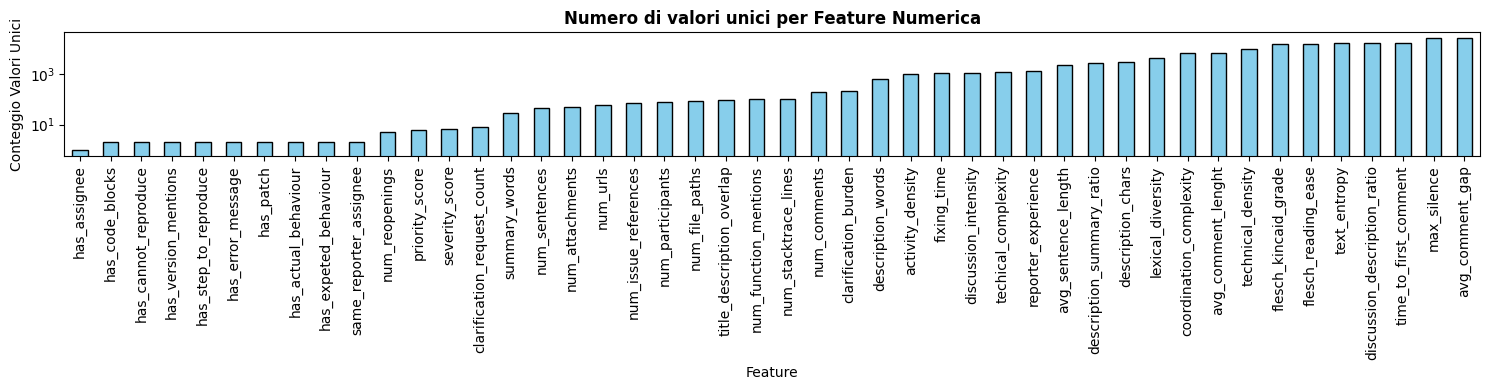

You seem to have 0 duplicates in your database.
Dimensioni del dataset dopo la rimozione dei duplicati: (26334, 46)


<Figure size 1000x600 with 0 Axes>

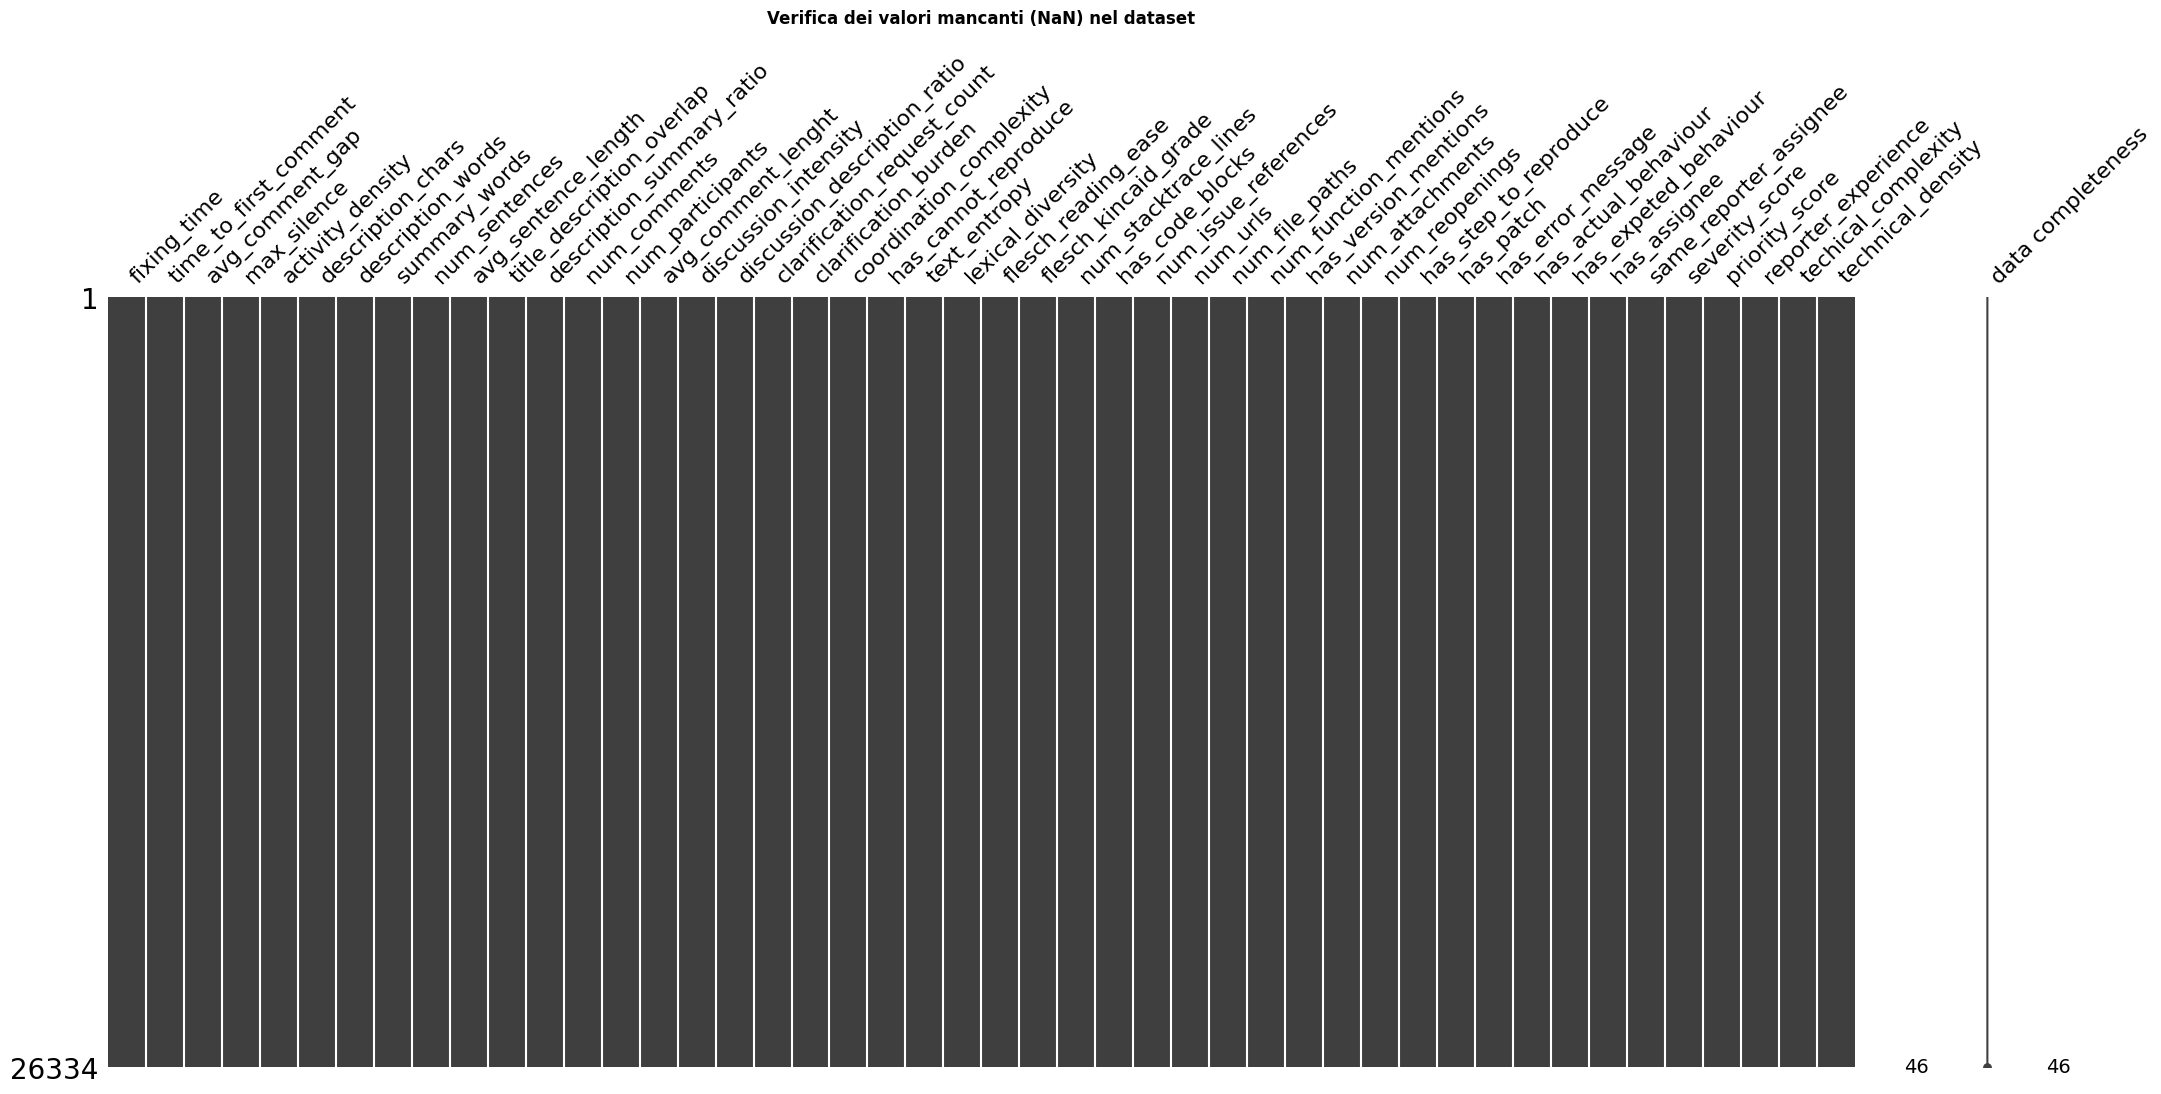

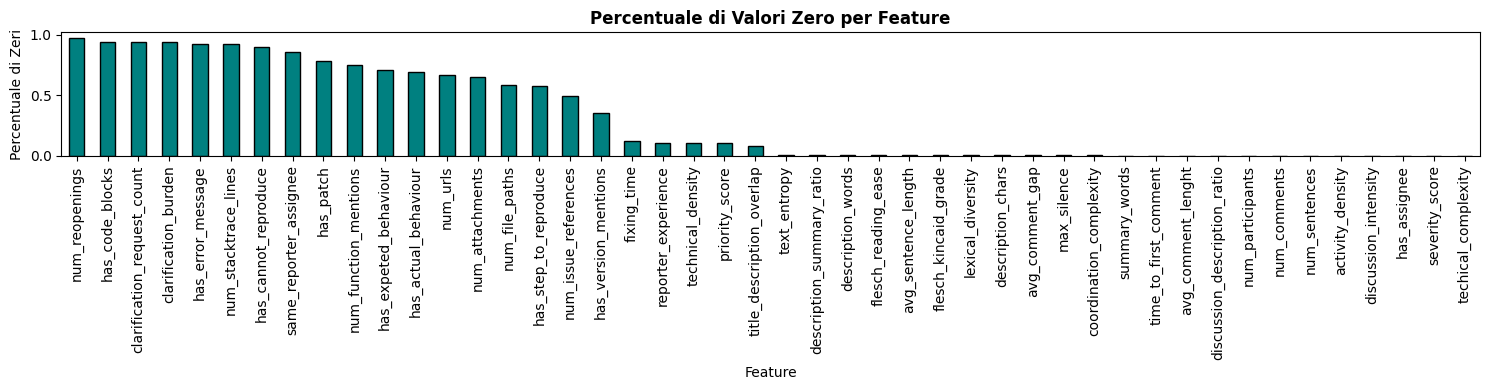

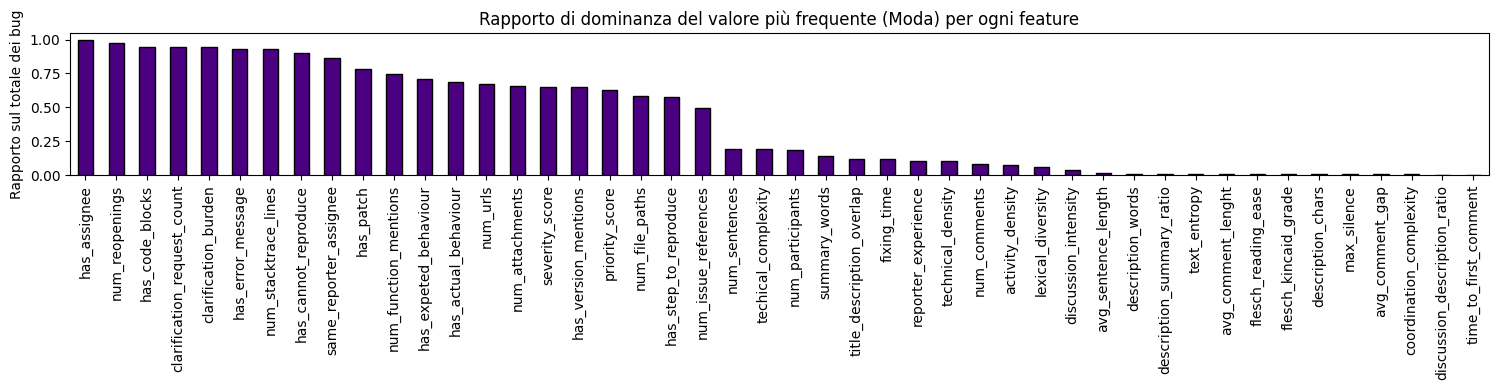

Grafico riassuntivo globale ('global_view_completa.png') generato con griglia 12x4.


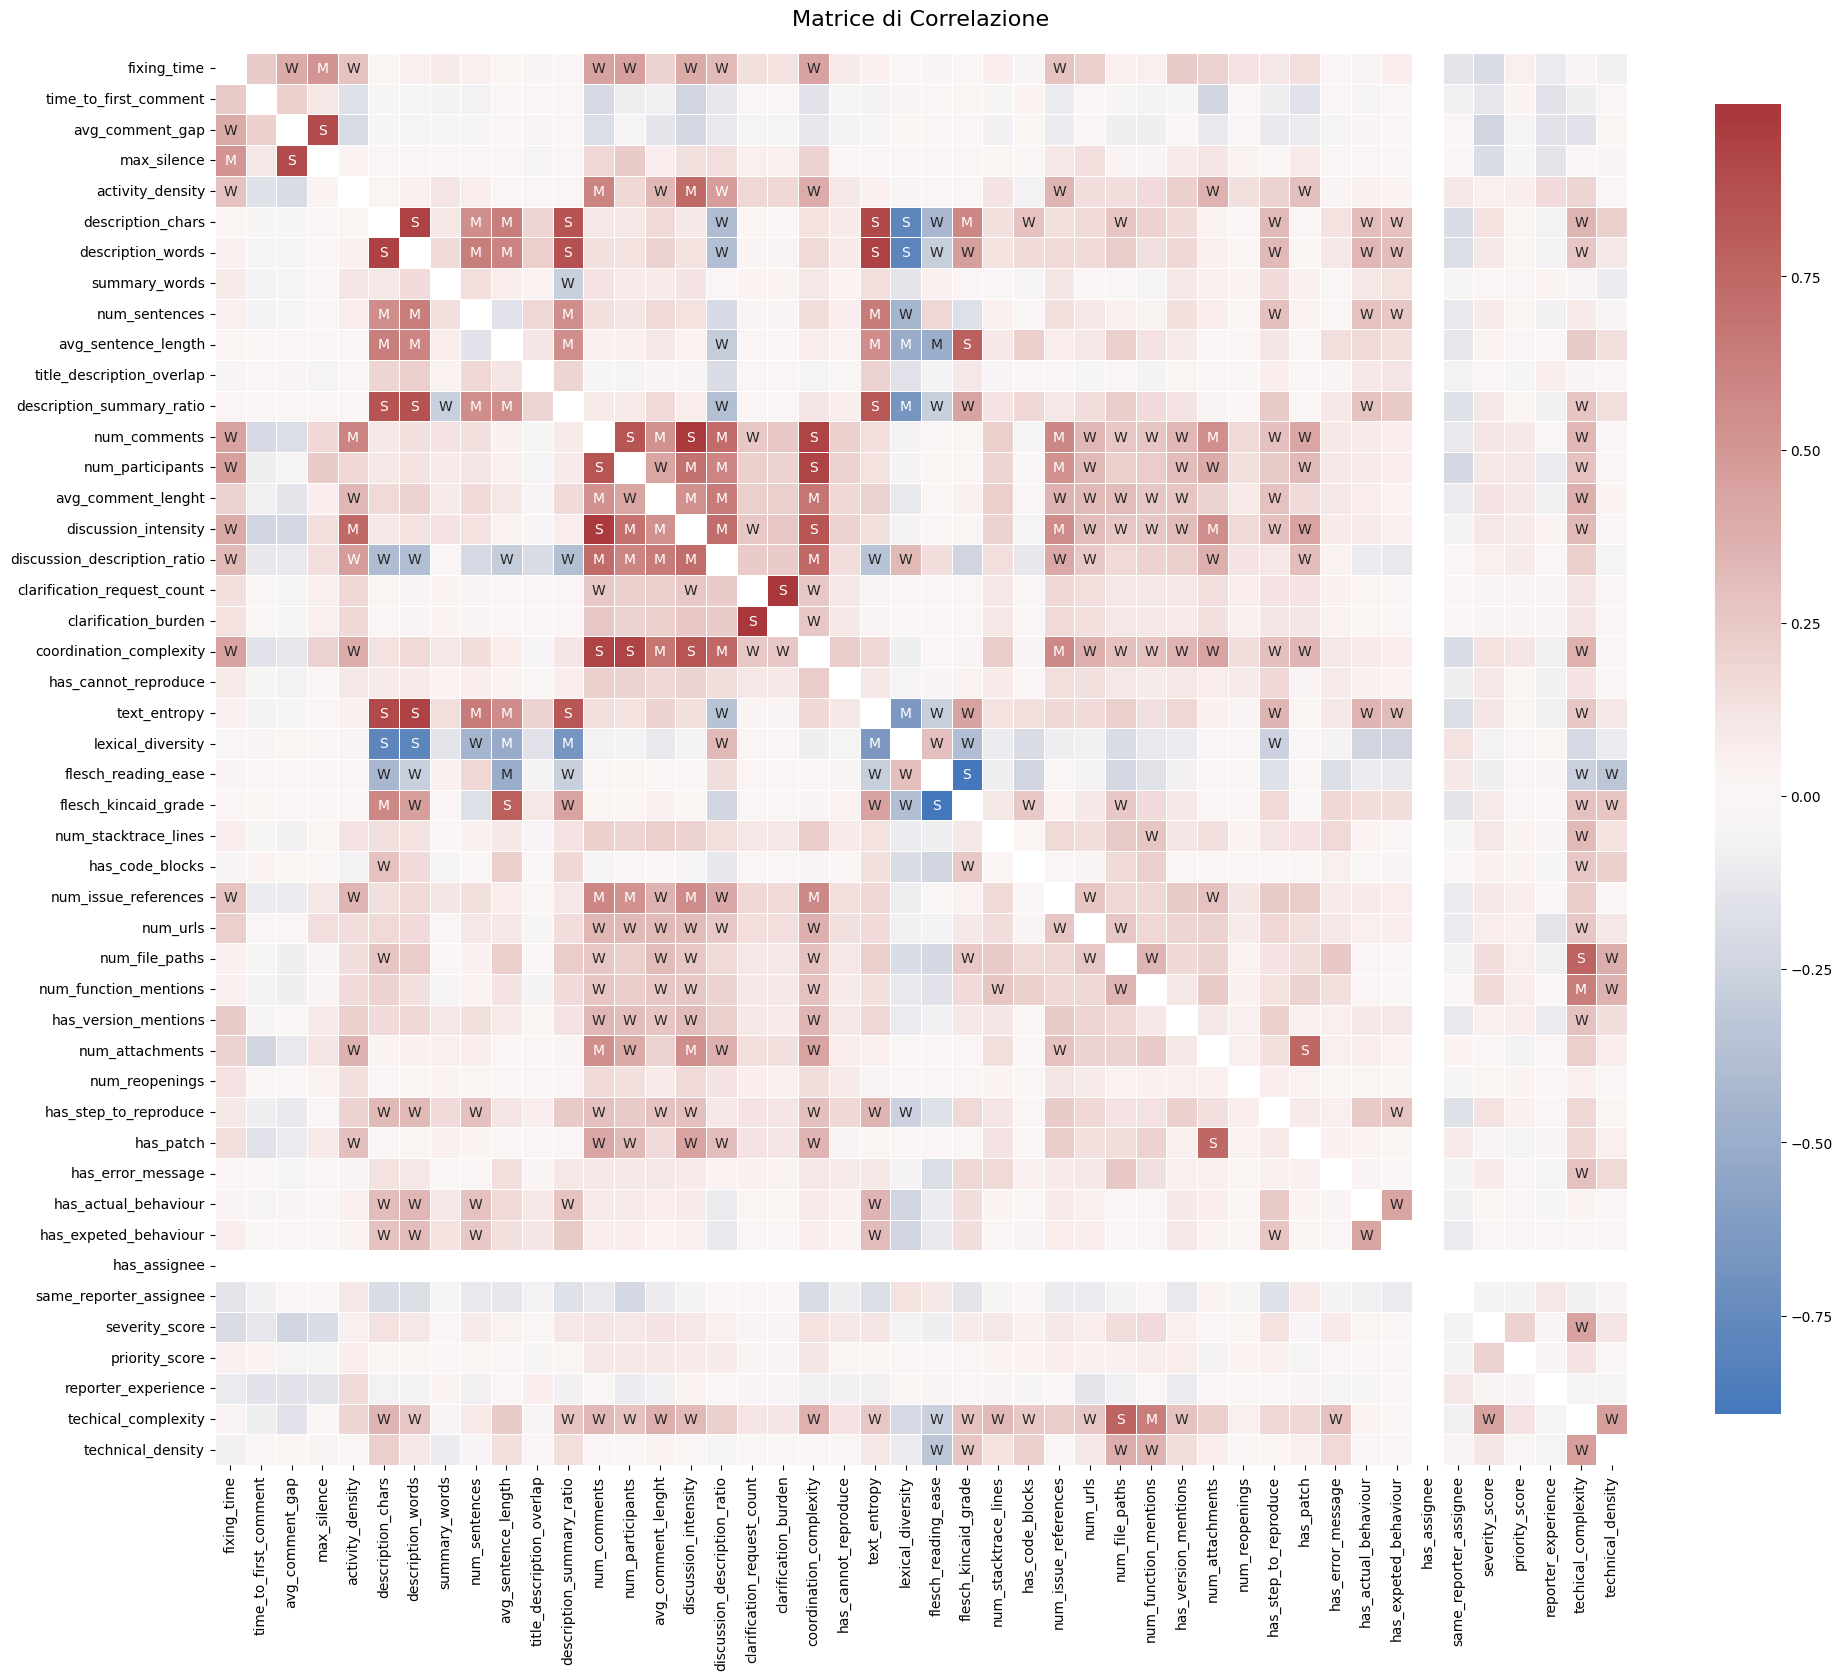


CORRELAZIONE DELLE FEATURE CON fixing_time
max_silence                     0.509575
num_participants                0.459027
coordination_complexity         0.445282
num_comments                    0.445136
avg_comment_gap                 0.406348
discussion_intensity            0.398628
discussion_description_ratio    0.320824
activity_density                0.284436
num_issue_references            0.280097
time_to_first_comment           0.244754
has_version_mentions            0.232539
num_urls                        0.222202
num_attachments                 0.197550
avg_comment_lenght              0.196078
has_patch                       0.147221
clarification_request_count     0.135300
clarification_burden            0.130999
num_reopenings                  0.119941
has_step_to_reproduce           0.102324
has_cannot_reproduce            0.080716
summary_words                   0.077690
has_expeted_behaviour           0.067591
num_stacktrace_lines            0.066553
num_function_

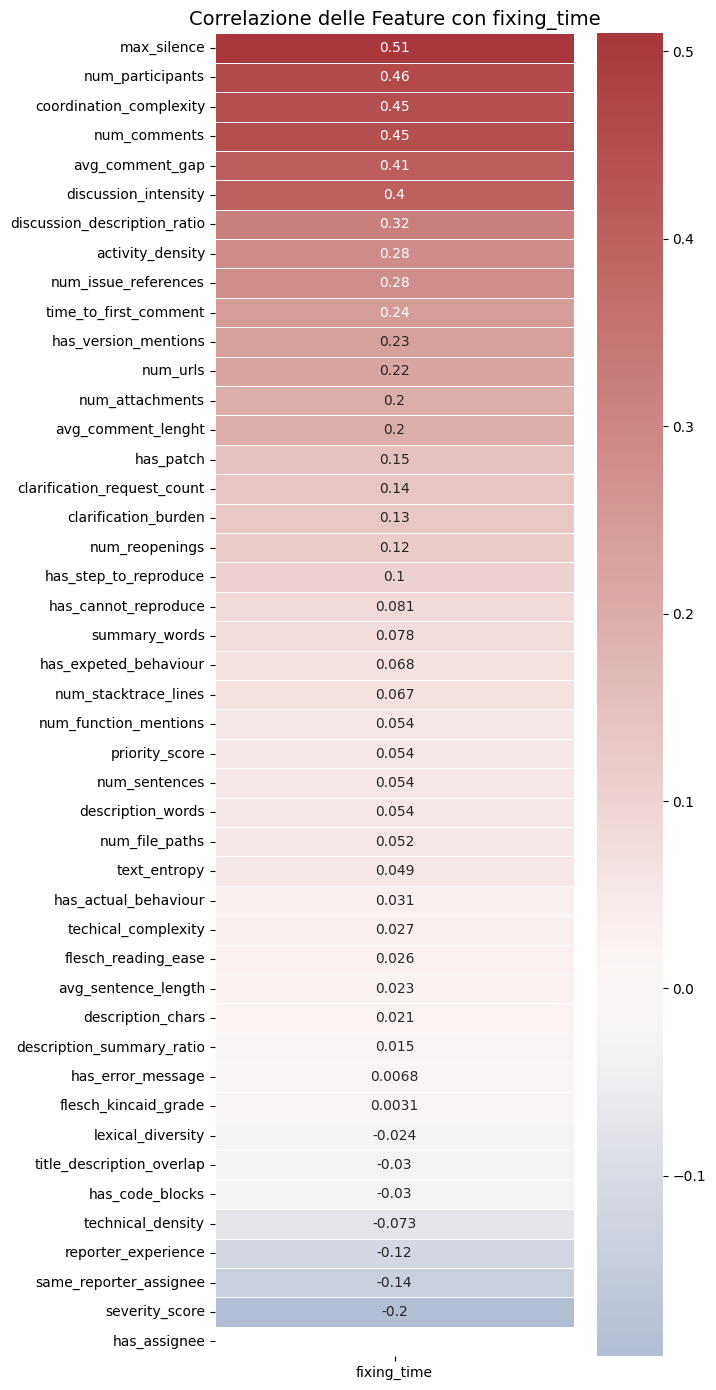


TOP 30 CORRELAZIONI TRA FEATURE
clarification_burden          clarification_request_count     0.999196
discussion_intensity          num_comments                    0.970581
description_words             description_chars               0.945781
text_entropy                  description_words               0.944706
coordination_complexity       num_comments                    0.929955
                              num_participants                0.926497
text_entropy                  description_chars               0.903514
max_silence                   avg_comment_gap                 0.894542
flesch_kincaid_grade          flesch_reading_ease            -0.892656
description_summary_ratio     description_words               0.873291
                              description_chars               0.851963
coordination_complexity       discussion_intensity            0.839316
num_participants              num_comments                    0.837551
text_entropy                  description_su

In [1]:
import pandas as pd
import os
import missingno as msno
import matplotlib.pyplot as plt

# =====================================================================
# SEZIONE 1: CARICAMENTO DATI E PULIZIA ID
# =====================================================================

# Percorso al file CSV
path_to_csv = os.path.join("..", "data", "processed", "features.csv")

# Carichiamo il dataset impostando esplicitamente bug_id come INDICE
df = pd.read_csv(path_to_csv, index_col="bug_id")
print(f"Dimensioni del dataset originale (escluso bug_id dalle feature): {df.shape}")

# =====================================================================
# SEZIONE 2: STUDIO VALORI UNICI 
# =====================================================================
# Per ogni feature numerica, conta il numero di valori unici e ordina in ordine crescente.
# Viene adottata una soglia di 25 valori unici per distinguere tra feature discrete (<=25) e continue (>25).
unique_values = df.select_dtypes(include="number").nunique().sort_values()

# Visualizza il grafico del numero di valori unici per ogni feature numerica con y-axis in log-scale
plt.figure(figsize=(15, 4))
unique_values.plot.bar(logy=True, edgecolor="black", color="skyblue")
plt.title("Numero di valori unici per Feature Numerica", fontsize=12, weight='bold')
plt.ylabel("Conteggio Valori Unici")
plt.xlabel("Feature")
plt.tight_layout()
plt.show()

# =====================================================================
# SEZIONE 3: GESTIONE RIGHE DUPLICATE
# rimuove righe con valori identici in tutte le feature 
# =====================================================================
n_duplicates = df.duplicated().sum()
print(f"You seem to have {n_duplicates} duplicates in your database.")

df_X = df.drop_duplicates()
print(f"Dimensioni del dataset dopo la rimozione dei duplicati: {df_X.shape}")

# =====================================================================
# SEZIONE 4: ANALISI DEI MISSING VALUES E DEGLI ZERI
# =====================================================================

# Genera la matrice dei missing values (sarà vuota/perfetta)
plt.figure(figsize=(10, 6))
msno.matrix(df_X, labels=True)
plt.title("Verifica dei valori mancanti (NaN) nel dataset", fontsize=12, weight='bold', pad=20)
plt.show()

# Calcola la percentuale di '0' per ogni feature
zero_ratio = (df_X == 0).mean().sort_values(ascending=False)

# Grafico a barre delle percentuali di zeri
plt.figure(figsize=(15, 4))
zero_ratio.plot(kind="bar", edgecolor="black", color="teal")
plt.title("Percentuale di Valori Zero per Feature", fontsize=12, weight='bold')
plt.ylabel("Percentuale di Zeri")
plt.xlabel("Feature")
plt.tight_layout()
plt.show()


# =====================================================================
# SEZIONE 5:ANALISI DELLA DOMINANZA DELLA MODA 
# grafico a barre verticali che mostra la percentuale di bug che condividono il valore più frequente (Moda)
#  per ogni feature numerica
# =====================================================================
df_dist = df_X.select_dtypes(include="number")
if "bug_id" in df_dist.columns:
    df_dist = df_dist.drop(columns=["bug_id"])

# Calcola il valore più comune (Moda)
most_frequent_entry = df_dist.mode()

# Calcola la percentuale di righe che contengono quel valore esatto
df_freq = df_dist.eq(most_frequent_entry.iloc[0], axis=1).mean().sort_values(ascending=False)

plt.figure(figsize=(15, 4))
df_freq.plot(kind="bar", color="indigo", edgecolor="black")
plt.title("Rapporto di dominanza del valore più frequente (Moda) per ogni feature")
plt.ylabel("Rapporto sul totale dei bug")
plt.tight_layout()
plt.savefig("dominanza_moda_features.png", dpi=300, bbox_inches='tight')
plt.show()


# =====================================================================
# SEZIONE 6 - Screening globale ed esportazione dell'Immagine Totale
# =====================================================================

df_global_view = df_X.select_dtypes(include="number").copy()
colonne_da_escludere = ["bug_id", "fixing_time"]
df_global_view = df_global_view.drop(columns=[c for c in colonne_da_escludere if c in df_global_view.columns])

all_features = list(df_global_view.columns)
total_features = len(all_features)

# ---------------------------------------------------------------------
# GENERA I GRAFICI A BLOCCHI DA 4 (Già presente, mantenuto per la tesi)
# ---------------------------------------------------------------------
chunk_size = 4
for i in range(0, total_features, chunk_size):
    current_chunk = all_features[i : i + chunk_size]
    parte_numero = (i // chunk_size) + 1
    
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    axes = axes.flatten()
    
    for idx, feature_name in enumerate(current_chunk):
        axes[idx].plot(df_global_view[feature_name].values, lw=0, marker=".", markersize=0.5, color="darkblue")
        axes[idx].set_title(feature_name, fontsize=10, weight='bold')
        axes[idx].set_xlabel("Indice Bug Report", fontsize=8)
        axes[idx].set_ylabel("Valore Feature", fontsize=8)
        axes[idx].grid(True, linestyle="--", alpha=0.3)
        
    for j in range(len(current_chunk), len(axes)):
        fig.delaxes(axes[j])
        
    plt.tight_layout()
    plt.savefig(f"global_view_parte{parte_numero}.png", dpi=300, bbox_inches='tight')
    plt.close()

# ---------------------------------------------------------------------
# NUOVO BLOCCO: Generazione dell'Immagine Unica Globale (Mosaico Completo)
# ---------------------------------------------------------------------
# Configura una griglia automatica a 4 colonne fisse
import math
n_cols = 4
n_rows = math.ceil(total_features / n_cols)

# Calcola una dimensione proporzionale (es. 5 pollici in larghezza e 3.5 in altezza per grafico)
fig_total, axes_total = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.5 * n_rows))
axes_total = axes_total.flatten()

for idx, feature_name in enumerate(all_features):
    axes_total[idx].plot(df_global_view[feature_name].values, lw=0, marker=".", markersize=0.3, color="darkblue")
    axes_total[idx].set_title(feature_name, fontsize=11, weight='bold')
    axes_total[idx].set_xlabel("Indice Bug Report", fontsize=9)
    axes_total[idx].set_ylabel("Valore Feature", fontsize=9)
    axes_total[idx].grid(True, linestyle="--", alpha=0.3)
    # Ottimizzazione: riduce leggermente la dimensione dei numeri sugli assi per evitare collisioni nel mosaico
    axes_total[idx].tick_params(axis='both', which='major', labelsize=8)

# Rimuove i quadranti rimasti vuoti se il numero totale di feature non è un multiplo esatto di 4
for j in range(total_features, len(axes_total)):
    fig_total.delaxes(axes_total[j])

# Layout compresso e salvataggio ad altissima definizione (dpi=300 o superiore per stampe vettoriali)
plt.tight_layout()
plt.savefig("global_view_completa.png", dpi=300, bbox_inches='tight')
print(f"Grafico riassuntivo globale ('global_view_completa.png') generato con griglia {n_rows}x{n_cols}.")
plt.close()


# =====================================================================
# SEZIONE 8: MATRICE DI CORRELAZIONE COMPLETA
# Correlazione tra TUTTE le feature + fixing_time
# (continue, discrete, binarie)
# =====================================================================

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# Seleziona tutte le feature numeriche
df_corr = df_X.select_dtypes(include="number").copy()

# Rimuove bug_id se presente
if "bug_id" in df_corr.columns:
    df_corr = df_corr.drop(columns=["bug_id"])


# =====================================================================
# MATRICE DI CORRELAZIONE COMPLETA (SPEARMAN)
# =====================================================================
# Spearman è più robusto perché:
# - gestisce continue
# - discrete
# - binarie
# - relazioni monotone non lineari
# =====================================================================

corr_matrix = df_corr.corr(method="spearman")

# ---------------------------------------------------------------------
# CREAZIONE ETICHETTE QUALITATIVE
# S = Strong
# M = Medium
# W = Weak
# ---------------------------------------------------------------------

labels = np.where(np.abs(corr_matrix) > 0.75, "S",
          np.where(np.abs(corr_matrix) > 0.50, "M",
          np.where(np.abs(corr_matrix) > 0.25, "W", "")))

# =====================================================================
# HEATMAP GLOBALE
# =====================================================================

plt.figure(figsize=(20, 18))
sns.heatmap(
    corr_matrix,
    mask=np.eye(len(corr_matrix)),
    square=True,
    center=0,
    annot=labels,
    fmt='',
    linewidths=.5,
    cmap="vlag",
    cbar_kws={"shrink": 0.8}
)
plt.title(
    "Matrice di Correlazione",
    fontsize=16,
    pad=20
)
plt.tight_layout()
plt.savefig(
    "heatmap_correlazione_completa_spearman.png",
    dpi=300,
    bbox_inches='tight'
)
plt.show()

# CORRELAZIONE CON fixing_time

target_corr = (
    corr_matrix["fixing_time"]
    .drop("fixing_time")
    .sort_values(ascending=False)
)
df_corr_to_save = target_corr.reset_index()
df_corr_to_save.columns = ['feature', 'correlation']

print("\n===================================================")
print("CORRELAZIONE DELLE FEATURE CON fixing_time")
print("===================================================")

print(target_corr)

# HEATMAP MIRATA ALLA TARGET

plt.figure(figsize=(7, 14))

sns.heatmap(
    target_corr.to_frame(),
    annot=True,
    cmap="vlag",
    center=0,
    linewidths=.5
)

plt.title(
    "Correlazione delle Feature con fixing_time",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "correlazione_feature_fixing_time.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# TOP CORRELAZIONI TRA FEATURE


lower_triangle = np.tril(np.ones(corr_matrix.shape), k=-1).astype(bool)

top_feature_corr = (
    corr_matrix.where(lower_triangle)
    .stack()
    .sort_values(key=abs, ascending=False)
)

print("\n===================================================")
print("TOP 30 CORRELAZIONI TRA FEATURE")
print("===================================================")

print(top_feature_corr.head(30))

# SALVATAGGIO CSV DELLE CORRELAZIONI

df_corr_to_save.to_csv("correlation_with_fixing_time.csv", index=False)

corr_matrix.to_csv("complete_correlation_matrix.csv")

print("\nFile CSV salvati correttamente.")
